In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [3]:
df = pd.read_csv('data/Telco_Churn.csv')

df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.select_dtypes(exclude='number').columns)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')
df.totalcharges = df.totalcharges.fillna(0)

df.churn = (df.churn == 'yes').astype(int)

In [4]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

del df_train['churn']
del df_val['churn']
del df_test['churn']

In [5]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

categorical = [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
]

In [6]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

model = LogisticRegression()
model.fit(X_train, y_train)

/home/devaa/ml-zoomcamp-2026/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [7]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)
(y_val == churn_decision).mean()

np.float64(0.801277501774308)

In [8]:
from sklearn.metrics import accuracy_score
from collections import Counter

In [9]:
thresholds = np.linspace(0,1,21)
scores = []
for t in thresholds:
    score = accuracy_score(y_val,y_pred>=t)
    scores.append(score)
    print("%.2f %.3f" % (t, score))


0.00 0.274
0.05 0.509
0.10 0.598
0.15 0.664
0.20 0.707
0.25 0.737
0.30 0.759
0.35 0.766
0.40 0.780
0.45 0.793
0.50 0.801
0.55 0.798
0.60 0.797
0.65 0.784
0.70 0.765
0.75 0.744
0.80 0.730
0.85 0.726
0.90 0.726
0.95 0.726
1.00 0.726


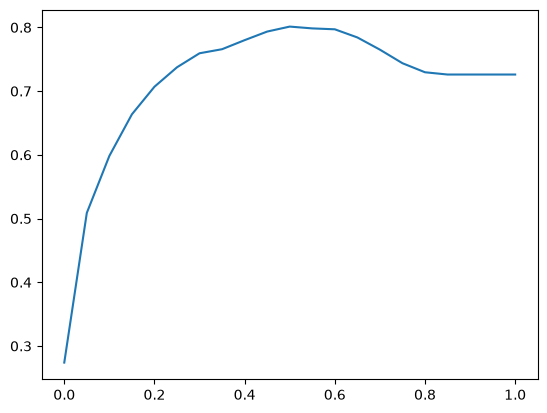

In [10]:
plt.plot(thresholds, scores)

In [11]:
print(Counter(y_val))
print(Counter(y_pred >= 0.5))
print(y_val.mean())  #percent churned

Counter({np.int64(0): 1023, np.int64(1): 386})
Counter({np.False_: 1087, np.True_: 322})
0.2739531582682754


CONFUSION MATRIX

In [12]:
actual_positive = (y_val==1)
actual_negative = (y_val==0)
t=0.5
predicted_positive = (y_pred >= t)
predicted_negative = (y_pred < t)

In [13]:
tp = (actual_positive & predicted_positive).sum()  # true positive
tn = (actual_negative & predicted_negative).sum()  # true negative
fp = (actual_negative & predicted_positive).sum()  # false positive
fn = (actual_positive & predicted_negative).sum()  # false negative

In [14]:
confusion_matrix = np.array([[tn, fp], [fn, tp]])
print(confusion_matrix)
print(confusion_matrix / confusion_matrix.sum())  # normalized

[[915 108]
 [172 214]]
[[0.64939674 0.07665011]
 [0.12207239 0.15188077]]


above we once more see approx 80% accuracy

also fn>fp => although model says will not churn customers churn and this happens more often than the opposite

PRECISION AND RECALL

P -> Fraction of positive predictions that are correct = tp/(tp + fp)

R -> Fraction of correctly identified positive examples = tp/(tp + fn)

In [15]:
p = tp/(tp+fp)
p

np.float64(0.6645962732919255)

In [16]:
r = tp/(tp+fn)
r

np.float64(0.5544041450777202)

here:
p = 66% means we sent 33%people mail when they were not going to churn
 r = 54% means model only identified 54% people who will churn. this is very poor and the earlier 80% accuracy is misleading

ROC
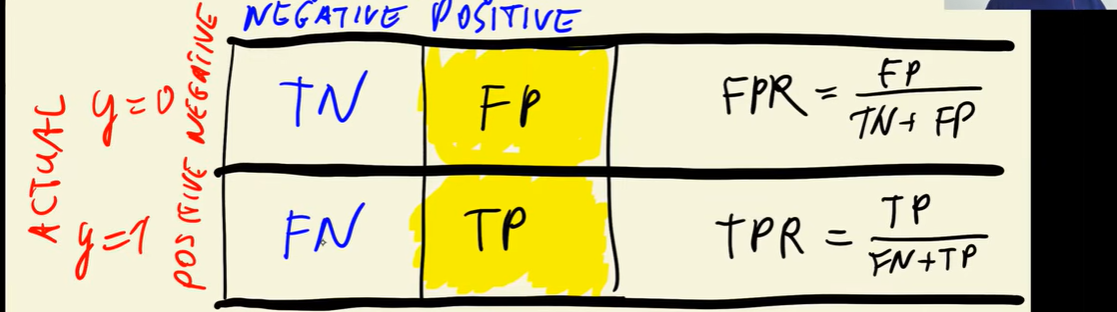

In [17]:
tpr = tp/(fn+tp)
fpr = fp/(tn+fp)

In [18]:
thresholds = np.linspace(0, 1, 101)
scores = []

for t in thresholds:
    predicted_positive = (y_pred >= t)
    predicted_negative = (y_pred < t)
    tp = (actual_positive & predicted_positive).sum()
    tn = (actual_negative & predicted_negative).sum()
    fp = (actual_negative & predicted_positive).sum()
    fn = (actual_positive & predicted_negative).sum()
    
    scores.append((t,tp,fp,fn,tn))

In [19]:
df_thresholds = pd.DataFrame(scores, columns=['threshold','tp','fp','fn','tn'])
df_thresholds[::10]

,threshold,tp,fp,fn,tn
0,0.0,386,1023,0,0
10,0.1,367,547,19,476
20,0.2,334,361,52,662
30,0.3,291,244,95,779
40,0.4,253,177,133,846
50,0.5,214,108,172,915
60,0.6,153,53,233,970
70,0.7,69,14,317,1009
80,0.8,5,0,381,1023
90,0.9,0,0,386,1023


In [20]:
df_thresholds['tpr'] = df_thresholds['tp'] / (df_thresholds['fn'] + df_thresholds['tp'])
df_thresholds['fpr'] = df_thresholds['fp'] / (df_thresholds['tn'] + df_thresholds['fp'])

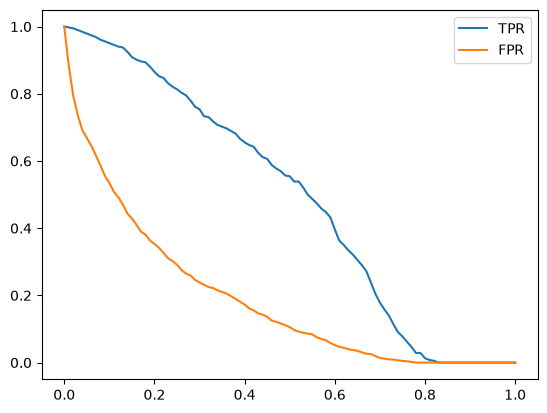

In [21]:
plt.plot(thresholds,df_thresholds.tpr,label='TPR')
plt.plot(thresholds,df_thresholds.fpr,label='FPR')
plt.legend()


Random Model

In [22]:
np.random.seed(1)
y_rand = np.random.uniform(0,1,size = len(y_val))
((y_rand>=0.5)==y_val).mean()

np.float64(0.5017743080198722)

In [23]:
def tpr_fpr_dataframe(y_val,y_pred):
    actual_positive = (y_val==1)
    actual_negative = (y_val==0)
    
    thresholds = np.linspace(0, 1, 101)
    scores = []

    for t in thresholds:
        predicted_positive = (y_pred >= t)
        predicted_negative = (y_pred < t)
        tp = (actual_positive & predicted_positive).sum()
        tn = (actual_negative & predicted_negative).sum()
        fp = (actual_negative & predicted_positive).sum()
        fn = (actual_positive & predicted_negative).sum()

        scores.append((t,tp,fp,fn,tn))

    df_thresholds = pd.DataFrame(scores, columns=['threshold','tp','fp','fn','tn'])
    df_thresholds['tpr'] = df_thresholds['tp'] / (df_thresholds['fn'] + df_thresholds['tp'])
    df_thresholds['fpr'] = df_thresholds['fp'] / (df_thresholds['tn'] + df_thresholds['fp'])
    
    return df_thresholds


In [24]:
df_rand = tpr_fpr_dataframe(y_val,y_rand)
df_rand[::10]

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,347,923,39,100,0.898964,0.902248
20,0.2,307,822,79,201,0.795337,0.803519
30,0.3,276,724,110,299,0.715026,0.707722
40,0.4,237,624,149,399,0.613990,0.609971
50,0.5,202,518,184,505,0.523316,0.506354
60,0.6,161,409,225,614,0.417098,0.399804
70,0.7,121,302,265,721,0.313472,0.295210
80,0.8,78,206,308,817,0.202073,0.201369
90,0.9,40,101,346,922,0.103627,0.098729


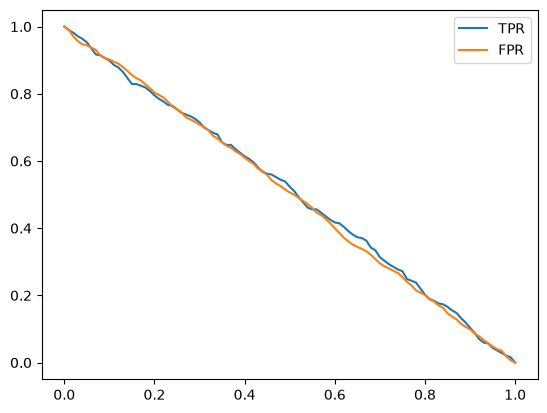

In [25]:
plt.plot(thresholds,df_rand.tpr,label='TPR')
plt.plot(thresholds,df_rand.fpr,label='FPR')
plt.legend()

Ideal Model

In [26]:
num_neg = (y_val==0).sum()
num_pos = (y_val==1).sum()
y_ideal = np.repeat([0,1], [num_neg,num_pos])
y_ideal_pred = np.linspace(0,1,len(y_val))

print(((y_ideal_pred>=0.726)==y_ideal).mean())

1.0


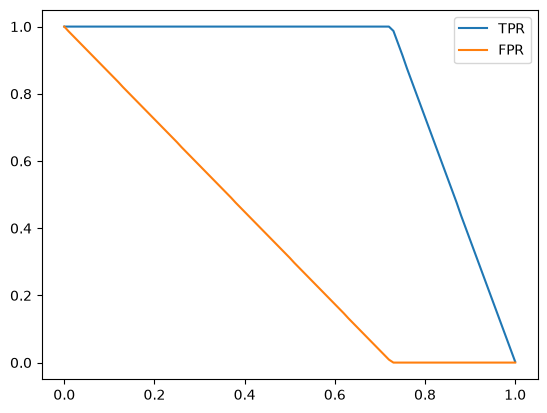

In [27]:
df_ideal = tpr_fpr_dataframe(y_ideal,y_ideal_pred)

plt.plot(thresholds,df_ideal.tpr,label='TPR')
plt.plot(thresholds,df_ideal.fpr,label='FPR')
plt.legend()

comparing with our actual graph , we want to incerease tpr.
we also learn that best threshold = 0.726

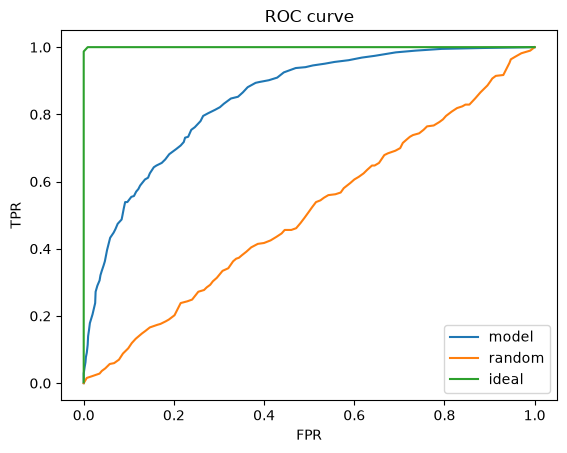

In [28]:
plt.figsize=(6,6)
plt.plot(df_thresholds.fpr,df_thresholds.tpr,label="model")
plt.plot(df_rand.fpr,df_rand.tpr,label="random")
plt.plot(df_ideal.fpr,df_ideal.tpr,label="ideal")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC curve")
plt.legend()

In [29]:
from sklearn.metrics import roc_curve

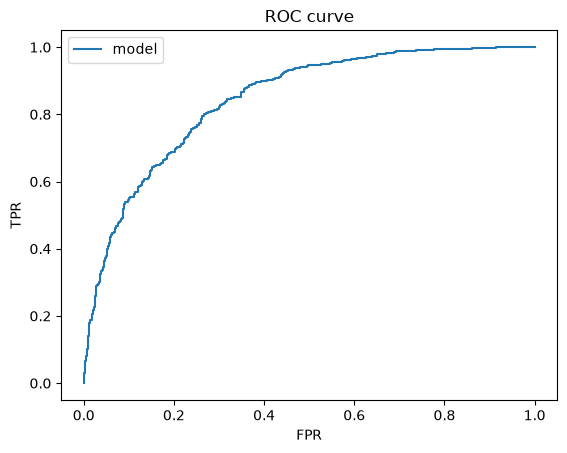

In [30]:
fpr,tpr,thresholds = roc_curve(y_val,y_pred)
plt.figsize=(6,6)
plt.plot(fpr,tpr,label="model")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC curve")
plt.legend()

ROC AREA UNDER THE CURVE

In [31]:
from sklearn.metrics import auc #area under curve

In [32]:
print(auc(fpr,tpr)) #x,y
print(auc(df_thresholds.fpr,df_thresholds.tpr)) #x,y
print(auc(df_rand.fpr,df_rand.tpr)) #x,y
print(auc(df_ideal.fpr,df_ideal.tpr)) #x,y

0.8445038720820102
0.8443696534119398
0.5060233793728696
0.9999430203759136


In [33]:
from sklearn.metrics import roc_auc_score

In [34]:
roc_auc_score(y_val,y_pred)

0.8445038720820102

In [35]:
neg = y_pred[y_val==0]
pos = y_pred[y_val==1]

In [36]:
import random

In [ ]:
n = 10000000
success=0
for i in range(n):
    pos_ind = random.randint(0,len(pos)-1)
    neg_ind = random.randint(0,len(neg)-1)
    if pos[pos_ind] > neg[neg_ind]:
        success += 1

success/n #very close to auc(fpr,tpr)

In [ ]:
#using numpy:
n = 10000000
pos_ind = np.random.randint(0,len(pos),size=n)
neg_ind = np.random.randint(0,len(neg),size=n)
success = (pos[pos_ind] > neg[neg_ind]).sum()
success/n #very close to auc(fpr,tpr)

np.float64(0.8445014)

Cross Validation
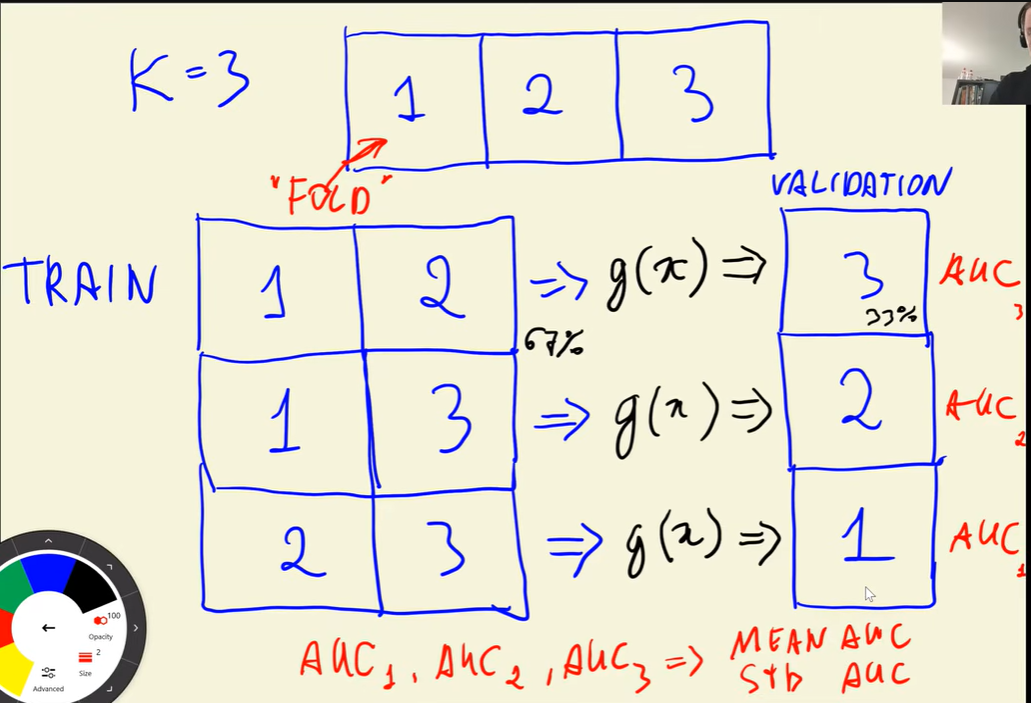

In [ ]:
def train(df,y,C=1.0):
    dicts = df[categorical + numerical].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)
    model = LogisticRegression(C=C)
    model.fit(X,y)

    return dv,model

In [ ]:
dv,model = train(df_train,y_train,C=10)

def predict(df,dv,model):
    dicts = df[categorical + numerical].to_dict(orient='records')
    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]
    return y_pred

/home/devaa/ml-zoomcamp-2026/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
y_pred = predict(df_val,dv,model)

In [ ]:
from sklearn.model_selection import KFold

In [ ]:
kfold = KFold(n_splits=10,shuffle=True,random_state=1)


scores =[]
for train_idx,val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.churn.values
    y_val = df_val.churn.values 

    dv,model = train(df_train,y_train)
    y_pred = predict(df_val,dv,model)
    auc = roc_auc_score(y_val,y_pred)

    scores.append(auc)